In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# Importing Required Python libraries

import pandas as pd # dataset handle korbo
import matplotlib.pyplot as plt # plot korbo
import seaborn as sns # correlation
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# loading dataset
dataset = pd.read_csv("/content/drive/MyDrive/Cse 111/E-commerce Shipping Dataset.csv")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
dataset.head(10)

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1
5,6,F,Flight,3,1,162,3,medium,F,12,1417,1
6,7,D,Flight,3,4,250,3,low,F,3,2371,1
7,8,F,Flight,4,1,233,2,low,F,48,2804,1
8,9,A,Flight,3,4,150,3,low,F,11,1861,1
9,10,B,Flight,3,2,164,3,medium,F,29,1187,1


In [ ]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (10999, 12). This dataset contains 10999 rows and 12 columns.


In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 
 10  Weight_in_gms        10999 non-null  int64 
 11  Reached.on.Time_Y.N  10999 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 1.0+ MB


In [ ]:
#### selecting numerical features
numerical_data = dataset.select_dtypes(include='number')
numerical_features=numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 8 numerical features: 

['ID', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N']


In [ ]:
#Selecting categoricalfeatures
categorical_data=dataset.select_dtypes(include= 'object')
categorical_features=categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 4 categorical features: 

['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


Data preprocessing Start

In [ ]:

print("\n--- Minimum and Maximum values for checking corrupt numbers ---")##checking if there are any corupt valuse or not?
print(dataset.describe().loc[['min', 'max']])


print("\n--- Unique values in Categorical Columns ---")
cat_cols = dataset.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"{col}: {dataset[col].unique()}")


--- Minimum and Maximum values for checking corrupt numbers ---
          ID  Customer_care_calls  Customer_rating  Cost_of_the_Product  \
min      1.0                  2.0              1.0                 96.0   
max  10999.0                  7.0              5.0                310.0   

     Prior_purchases  Discount_offered  Weight_in_gms  Reached.on.Time_Y.N  
min              2.0               1.0         1001.0                  0.0  
max             10.0              65.0         7846.0                  1.0  

--- Unique values in Categorical Columns ---
Warehouse_block: ['D' 'F' 'A' 'B' 'C']
Mode_of_Shipment: ['Flight' 'Ship' 'Road']
Product_importance: ['low' 'medium' 'high']
Gender: ['F' 'M']


In [ ]:
if 'ID' in dataset.columns:###Delete ID colum
    dataset = dataset.drop('ID', axis=1)
dataset.head(10)

,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,D,Flight,4,2,177,3,low,F,44,1233,1
1,F,Flight,4,5,216,2,low,M,59,3088,1
2,A,Flight,2,2,183,4,low,M,48,3374,1
3,B,Flight,3,3,176,4,medium,M,10,1177,1
4,C,Flight,2,2,184,3,medium,F,46,2484,1
5,F,Flight,3,1,162,3,medium,F,12,1417,1
6,D,Flight,3,4,250,3,low,F,3,2371,1
7,F,Flight,4,1,233,2,low,F,48,2804,1
8,A,Flight,3,4,150,3,low,F,11,1861,1
9,B,Flight,3,2,164,3,medium,F,29,1187,1


In [ ]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (10999, 11). This dataset contains 10999 rows and 11 columns.


In [ ]:
# PROBLEM 1: Null / Missing values
# ==========================================
missing_values = dataset.isnull().sum()
print("Missing values in each column:\n", missing_values)

Missing values in each column:
 Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64


In [ ]:
# PROBLEM 2: Categorical values

# Identify which columns are categorical (object type)
cat_cols = dataset.select_dtypes(include=['object']).columns.tolist()
print("\nCategorical columns to encode:", cat_cols)


Categorical columns to encode: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


In [ ]:
# 1. Warehouse_block= nominal; hence one hot encoding
dataset = pd.get_dummies(dataset, columns=['Warehouse_block'], drop_first=False)
dataset.head()

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))
dataset.head(5)

Shape of the dataset is (10999, 15). This dataset contains 10999 rows and 15 columns.


,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N,Warehouse_block_A,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F
0,Flight,4,2,177,3,low,F,44,1233,1,False,False,False,True,False
1,Flight,4,5,216,2,low,M,59,3088,1,False,False,False,False,True
2,Flight,2,2,183,4,low,M,48,3374,1,True,False,False,False,False
3,Flight,3,3,176,4,medium,M,10,1177,1,False,True,False,False,False
4,Flight,2,2,184,3,medium,F,46,2484,1,False,False,True,False,False


In [ ]:
# 2. Mode_of_Shipment = nominal; hence one hot encoding
dataset = pd.get_dummies(dataset, columns=['Mode_of_Shipment'], drop_first=False)
dataset.head()

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (10999, 17). This dataset contains 10999 rows and 17 columns.


In [ ]:
dataset.head(5)

,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N,Warehouse_block_A,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Flight,Mode_of_Shipment_Road,Mode_of_Shipment_Ship
0,4,2,177,3,low,F,44,1233,1,False,False,False,True,False,True,False,False
1,4,5,216,2,low,M,59,3088,1,False,False,False,False,True,True,False,False
2,2,2,183,4,low,M,48,3374,1,True,False,False,False,False,True,False,False
3,3,3,176,4,medium,M,10,1177,1,False,True,False,False,False,True,False,False
4,2,2,184,3,medium,F,46,2484,1,False,False,True,False,False,True,False,False


In [ ]:
dataset['Product_importance enc'] = dataset['Product_importance'].map({'low': 0, 'medium': 1, 'high': 2})
print(dataset[['Product_importance', 'Product_importance enc']].head(30))

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

   Product_importance  Product_importance enc
0                 low                       0
1                 low                       0
2                 low                       0
3              medium                       1
4              medium                       1
5              medium                       1
6                 low                       0
7                 low                       0
8                 low                       0
9              medium                       1
10             medium                       1
11             medium                       1
12             medium                       1
13               high                       2
14                low                       0
15                low                       0
16             medium                       1
17             medium                       1
18               high                       2
19             medium                       1
20             medium             

In [ ]:
# 4. Gender = nominal; hence one hot encoding
dataset = pd.get_dummies(dataset, columns=['Gender'], drop_first=False)
dataset.head()

print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (10999, 19). This dataset contains 10999 rows and 19 columns.


# Drop the feature without one hot encoding cz it has its own encoding **value**

In [ ]:
categorical_features = [
    "Product_importance"
]
dataset = dataset.drop(columns=categorical_features)

In [ ]:
dataset.head(4)

,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N,Warehouse_block_A,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Flight,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance enc,Gender_F,Gender_M
0,4,2,177,3,44,1233,1,False,False,False,True,False,True,False,False,0,True,False
1,4,5,216,2,59,3088,1,False,False,False,False,True,True,False,False,0,False,True
2,2,2,183,4,48,3374,1,True,False,False,False,False,True,False,False,0,False,True
3,3,3,176,4,10,1177,1,False,True,False,False,False,True,False,False,1,False,True


In [ ]:
# Shifting Target Column to the Last

# ১. 'Reached.on.Time_Y.N' kete target e rakhlam
target = dataset.pop('Reached.on.Time_Y.N')

# same name e save kore e last e rakhlam
dataset['Reached.on.Time_Y.N'] = target


dataset.head(5)

,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_A,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Flight,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance enc,Gender_F,Gender_M,Reached.on.Time_Y.N
0,4,2,177,3,44,1233,False,False,False,True,False,True,False,False,0,True,False,1
1,4,5,216,2,59,3088,False,False,False,False,True,True,False,False,0,False,True,1
2,2,2,183,4,48,3374,True,False,False,False,False,True,False,False,0,False,True,1
3,3,3,176,4,10,1177,False,True,False,False,False,True,False,False,1,False,True,1
4,2,2,184,3,46,2484,False,False,True,False,False,True,False,False,1,True,False,1


In [ ]:
dataset


,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_A,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Flight,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance enc,Gender_F,Gender_M,Reached.on.Time_Y.N
0,4,2,177,3,44,1233,False,False,False,True,False,True,False,False,0,True,False,1
1,4,5,216,2,59,3088,False,False,False,False,True,True,False,False,0,False,True,1
2,2,2,183,4,48,3374,True,False,False,False,False,True,False,False,0,False,True,1
3,3,3,176,4,10,1177,False,True,False,False,False,True,False,False,1,False,True,1
4,2,2,184,3,46,2484,False,False,True,False,False,True,False,False,1,True,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10994,4,1,252,5,1,1538,True,False,False,False,False,False,False,True,1,True,False,1
10995,4,1,232,5,6,1247,False,True,False,False,False,False,False,True,1,True,False,0
10996,5,4,242,5,4,1155,False,False,True,False,False,False,False,True,0,True,False,0
10997,5,2,223,6,2,1210,False,False,False,False,True,False,False,True,1,False,True,0


In [ ]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (10999, 18). This dataset contains 10999 rows and 18 columns.


# **Correlation to decide which feature affect the target mostly**

In [ ]:
dataset_corr = dataset.corr()
dataset_corr

,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_A,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Flight,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance enc,Gender_F,Gender_M,Reached.on.Time_Y.N
Customer_care_calls,1.000000,0.012209,0.323182,0.180771,-0.130750,-0.276615,-0.006375,-0.013428,0.004099,-0.000401,0.012732,0.019093,0.003292,-0.017629,-0.058134,-0.002545,0.002545,-0.067126
Customer_rating,0.012209,1.000000,0.009270,0.013179,-0.003124,-0.001897,-0.010471,-0.003222,0.001093,0.008687,0.003092,-0.002481,0.001516,0.000765,0.003999,-0.002775,0.002775,0.013119
Cost_of_the_Product,0.323182,0.009270,1.000000,0.123676,-0.138312,-0.132604,-0.013299,0.018260,0.009255,0.006618,-0.016472,-0.008130,0.002531,0.004419,-0.046789,-0.019759,0.019759,-0.073587
Prior_purchases,0.180771,0.013179,0.123676,1.000000,-0.082769,-0.168213,0.002979,0.002178,-0.003750,0.010095,-0.009095,-0.000263,0.003913,-0.002864,0.027317,0.009395,-0.009395,-0.055515
Discount_offered,-0.130750,-0.003124,-0.138312,-0.082769,1.000000,-0.376067,-0.004157,-0.005135,0.000736,-0.007714,0.012864,-0.005750,-0.007787,0.010643,0.026023,0.011777,-0.011777,0.397108
Weight_in_gms,-0.276615,-0.001897,-0.132604,-0.168213,-0.376067,1.000000,-0.005078,0.000461,0.002000,-0.001414,0.003187,-0.001245,0.004146,-0.002273,0.093211,-0.003573,0.003573,-0.268793
Warehouse_block_A,-0.006375,-0.010471,-0.013299,0.002979,-0.004157,-0.005078,1.000000,-0.199978,-0.199978,-0.200044,-0.316189,0.000570,0.000461,-0.000811,-0.007315,0.001911,-0.001911,-0.009317
Warehouse_block_B,-0.013428,-0.003222,0.018260,0.002178,-0.005135,0.000461,-0.199978,1.000000,-0.199978,-0.200044,-0.316189,-0.000093,0.000461,-0.000289,0.005997,-0.007847,0.007847,0.005106
Warehouse_block_C,0.004099,0.001093,0.009255,-0.003750,0.000736,0.002000,-0.199978,-0.199978,1.000000,-0.200044,-0.316189,-0.000755,0.000461,0.000233,0.007138,-0.001504,0.001504,0.000132
Warehouse_block_D,-0.000401,0.008687,0.006618,0.010095,-0.007714,-0.001414,-0.200044,-0.200044,-0.200044,1.000000,-0.316292,0.000463,-0.000976,0.000401,0.003104,0.004104,-0.004104,0.000830


<Axes: >

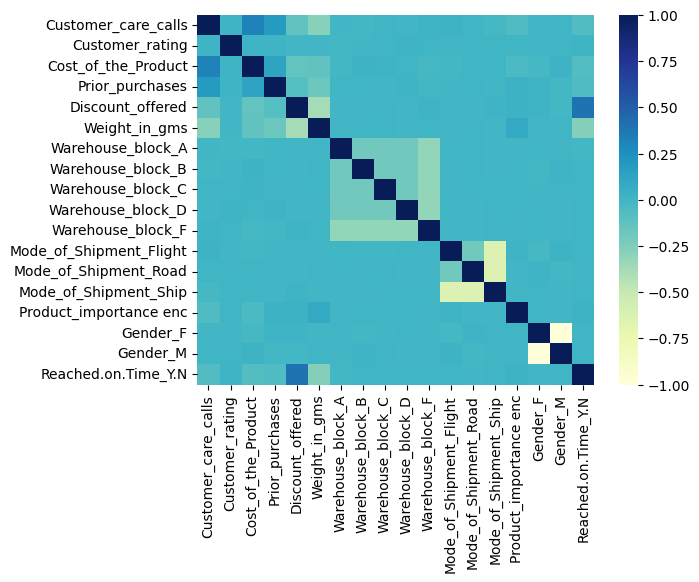

In [ ]:
sns.heatmap(dataset_corr, cmap = 'YlGnBu')

Check balance Imbalnce data for taget

Text(0.5, 1.0, 'Class Distribution of Target Feature (Reached.on.Time_Y.N)')

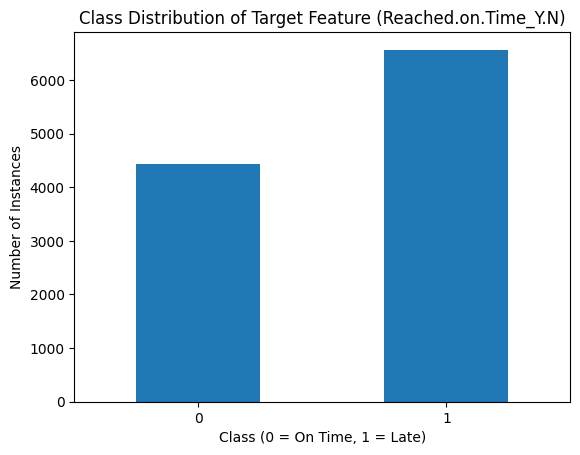

In [ ]:
import matplotlib.pyplot as plt

# Counting and plotting the class distribution for your target feature
dataset["Reached.on.Time_Y.N"].value_counts().sort_index().plot(
    kind="bar",
    xlabel="Class (0 = On Time, 1 = Late)",
    ylabel="Number of Instances",
    rot=0,

)

# Adding a title to the graph
plt.title("Class Distribution of Target Feature (Reached.on.Time_Y.N)")

#plt.show()

Descriptive Analysis
In descriptive Analysis we analysis each variable separately to get inference about the feature.
Summary satistics of Numerical Features

In [ ]:
# # Transposed stats for numerical features
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,10999.0,5500.000000,3175.282140,1.0,2750.5,5500.0,8249.5,10999.0
Customer_care_calls,10999.0,4.054459,1.141490,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,3.567597,1.522860,2.0,3.0,3.0,4.0,10.0
Discount_offered,10999.0,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0
Weight_in_gms,10999.0,3634.016729,1635.377251,1001.0,1839.5,4149.0,5050.0,7846.0
Reached.on.Time_Y.N,10999.0,0.596691,0.490584,0.0,0.0,1.0,1.0,1.0


In [ ]:
# Transposed stats for categorical features

categorical_data.describe().T

,count,unique,top,freq
Warehouse_block,10999,5,F,3666
Mode_of_Shipment,10999,3,Ship,7462
Product_importance,10999,3,low,5297
Gender,10999,2,F,5545


Varience of each feature

In [ ]:
numerical_data.var()

,0
ID,1.008242e+07
Customer_care_calls,1.302999e+00
Customer_rating,1.998274e+00
Cost_of_the_Product,2.310078e+03
Prior_purchases,2.319103e+00
Discount_offered,2.626191e+02
Weight_in_gms,2.674459e+06
Reached.on.Time_Y.N,2.406728e-01


In [ ]:
dataset.var()

,0
Customer_care_calls,1.302999e+00
Customer_rating,1.998274e+00
Cost_of_the_Product,2.310078e+03
Prior_purchases,2.319103e+00
Discount_offered,2.626191e+02
Weight_in_gms,2.674459e+06
Warehouse_block_A,1.388914e-01
Warehouse_block_B,1.388914e-01
Warehouse_block_C,1.388914e-01
Warehouse_block_D,1.389520e-01


In [ ]:
numerical_data.skew()

,0
ID,0.000000
Customer_care_calls,0.391926
Customer_rating,0.004360
Cost_of_the_Product,-0.157117
Prior_purchases,1.681897
Discount_offered,1.798929
Weight_in_gms,-0.249747
Reached.on.Time_Y.N,-0.394257


In [ ]:
dataset.skew()

,0
Customer_care_calls,0.391926
Customer_rating,0.004360
Cost_of_the_Product,-0.157117
Prior_purchases,1.681897
Discount_offered,1.798929
Weight_in_gms,-0.249747
Warehouse_block_A,1.789245
Warehouse_block_B,1.789245
Warehouse_block_C,1.789245
Warehouse_block_D,1.788367


Skew in numerical features
📐 What is Skewness? Skewness measures the asymmetry of the distribution of a dataset.

Skewness = 0 → Perfectly symmetrical (e.g., normal distribution)

Skewness < 0 → Left-skewed (long tail on the left)

Skewness > 0 → Right-skewed (long tail on the right)

It helps you understand how balanced your data is and whether transformations are needed.

📊 Interpretation of Skewness Values:

Skewness Value Interpretation

~ 0 Symmetrical (normal-ish)

0 to ±0.5 Fairly **symmetrical**

±0.5 to ±1 Moderately skewed

greater than ±1 Highly skewed **bold text**

# **Histogram and Box plot**

In [ ]:
dataset

,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_A,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Flight,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance enc,Gender_F,Gender_M,Reached.on.Time_Y.N
0,4,2,177,3,44,1233,False,False,False,True,False,True,False,False,0,True,False,1
1,4,5,216,2,59,3088,False,False,False,False,True,True,False,False,0,False,True,1
2,2,2,183,4,48,3374,True,False,False,False,False,True,False,False,0,False,True,1
3,3,3,176,4,10,1177,False,True,False,False,False,True,False,False,1,False,True,1
4,2,2,184,3,46,2484,False,False,True,False,False,True,False,False,1,True,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10994,4,1,252,5,1,1538,True,False,False,False,False,False,False,True,1,True,False,1
10995,4,1,232,5,6,1247,False,True,False,False,False,False,False,True,1,True,False,0
10996,5,4,242,5,4,1155,False,False,True,False,False,False,False,True,0,True,False,0
10997,5,2,223,6,2,1210,False,False,False,False,True,False,False,True,1,False,True,0


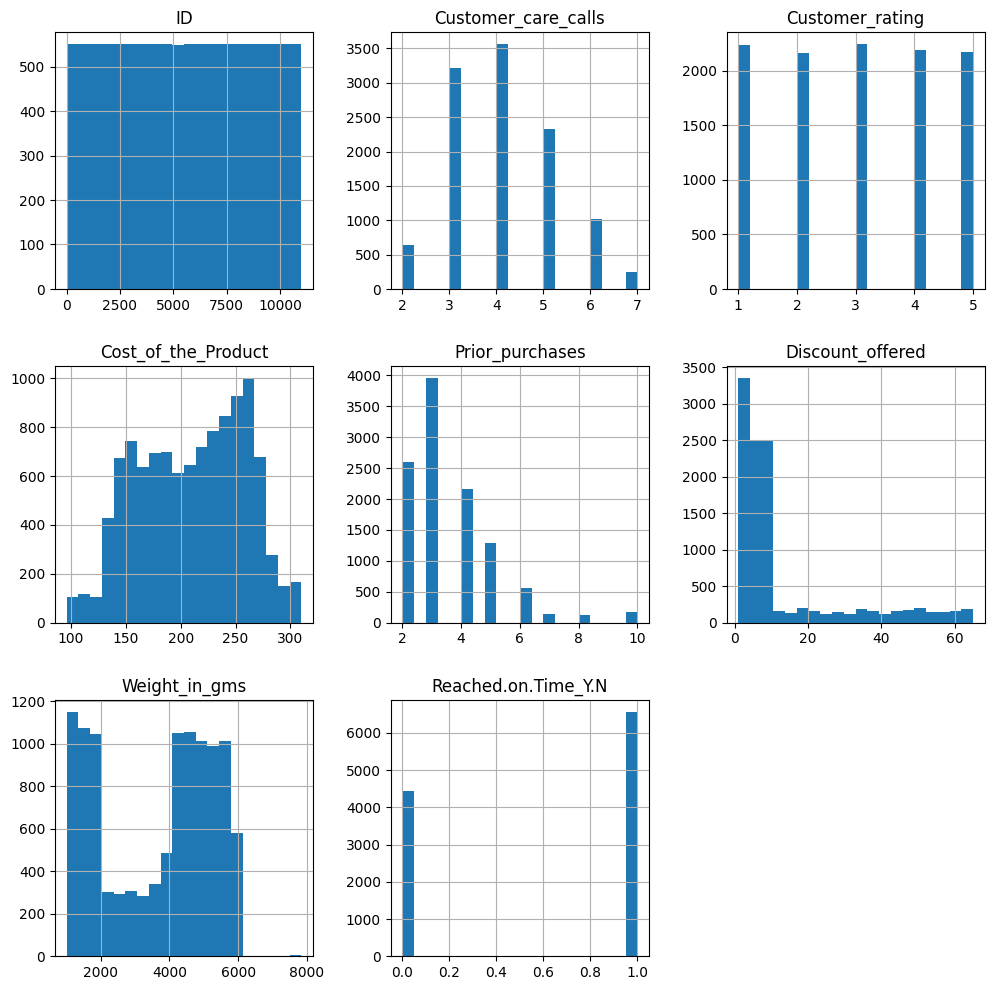

In [ ]:
numerical_data.hist(figsize=(12,12),bins=20)
plt.show()

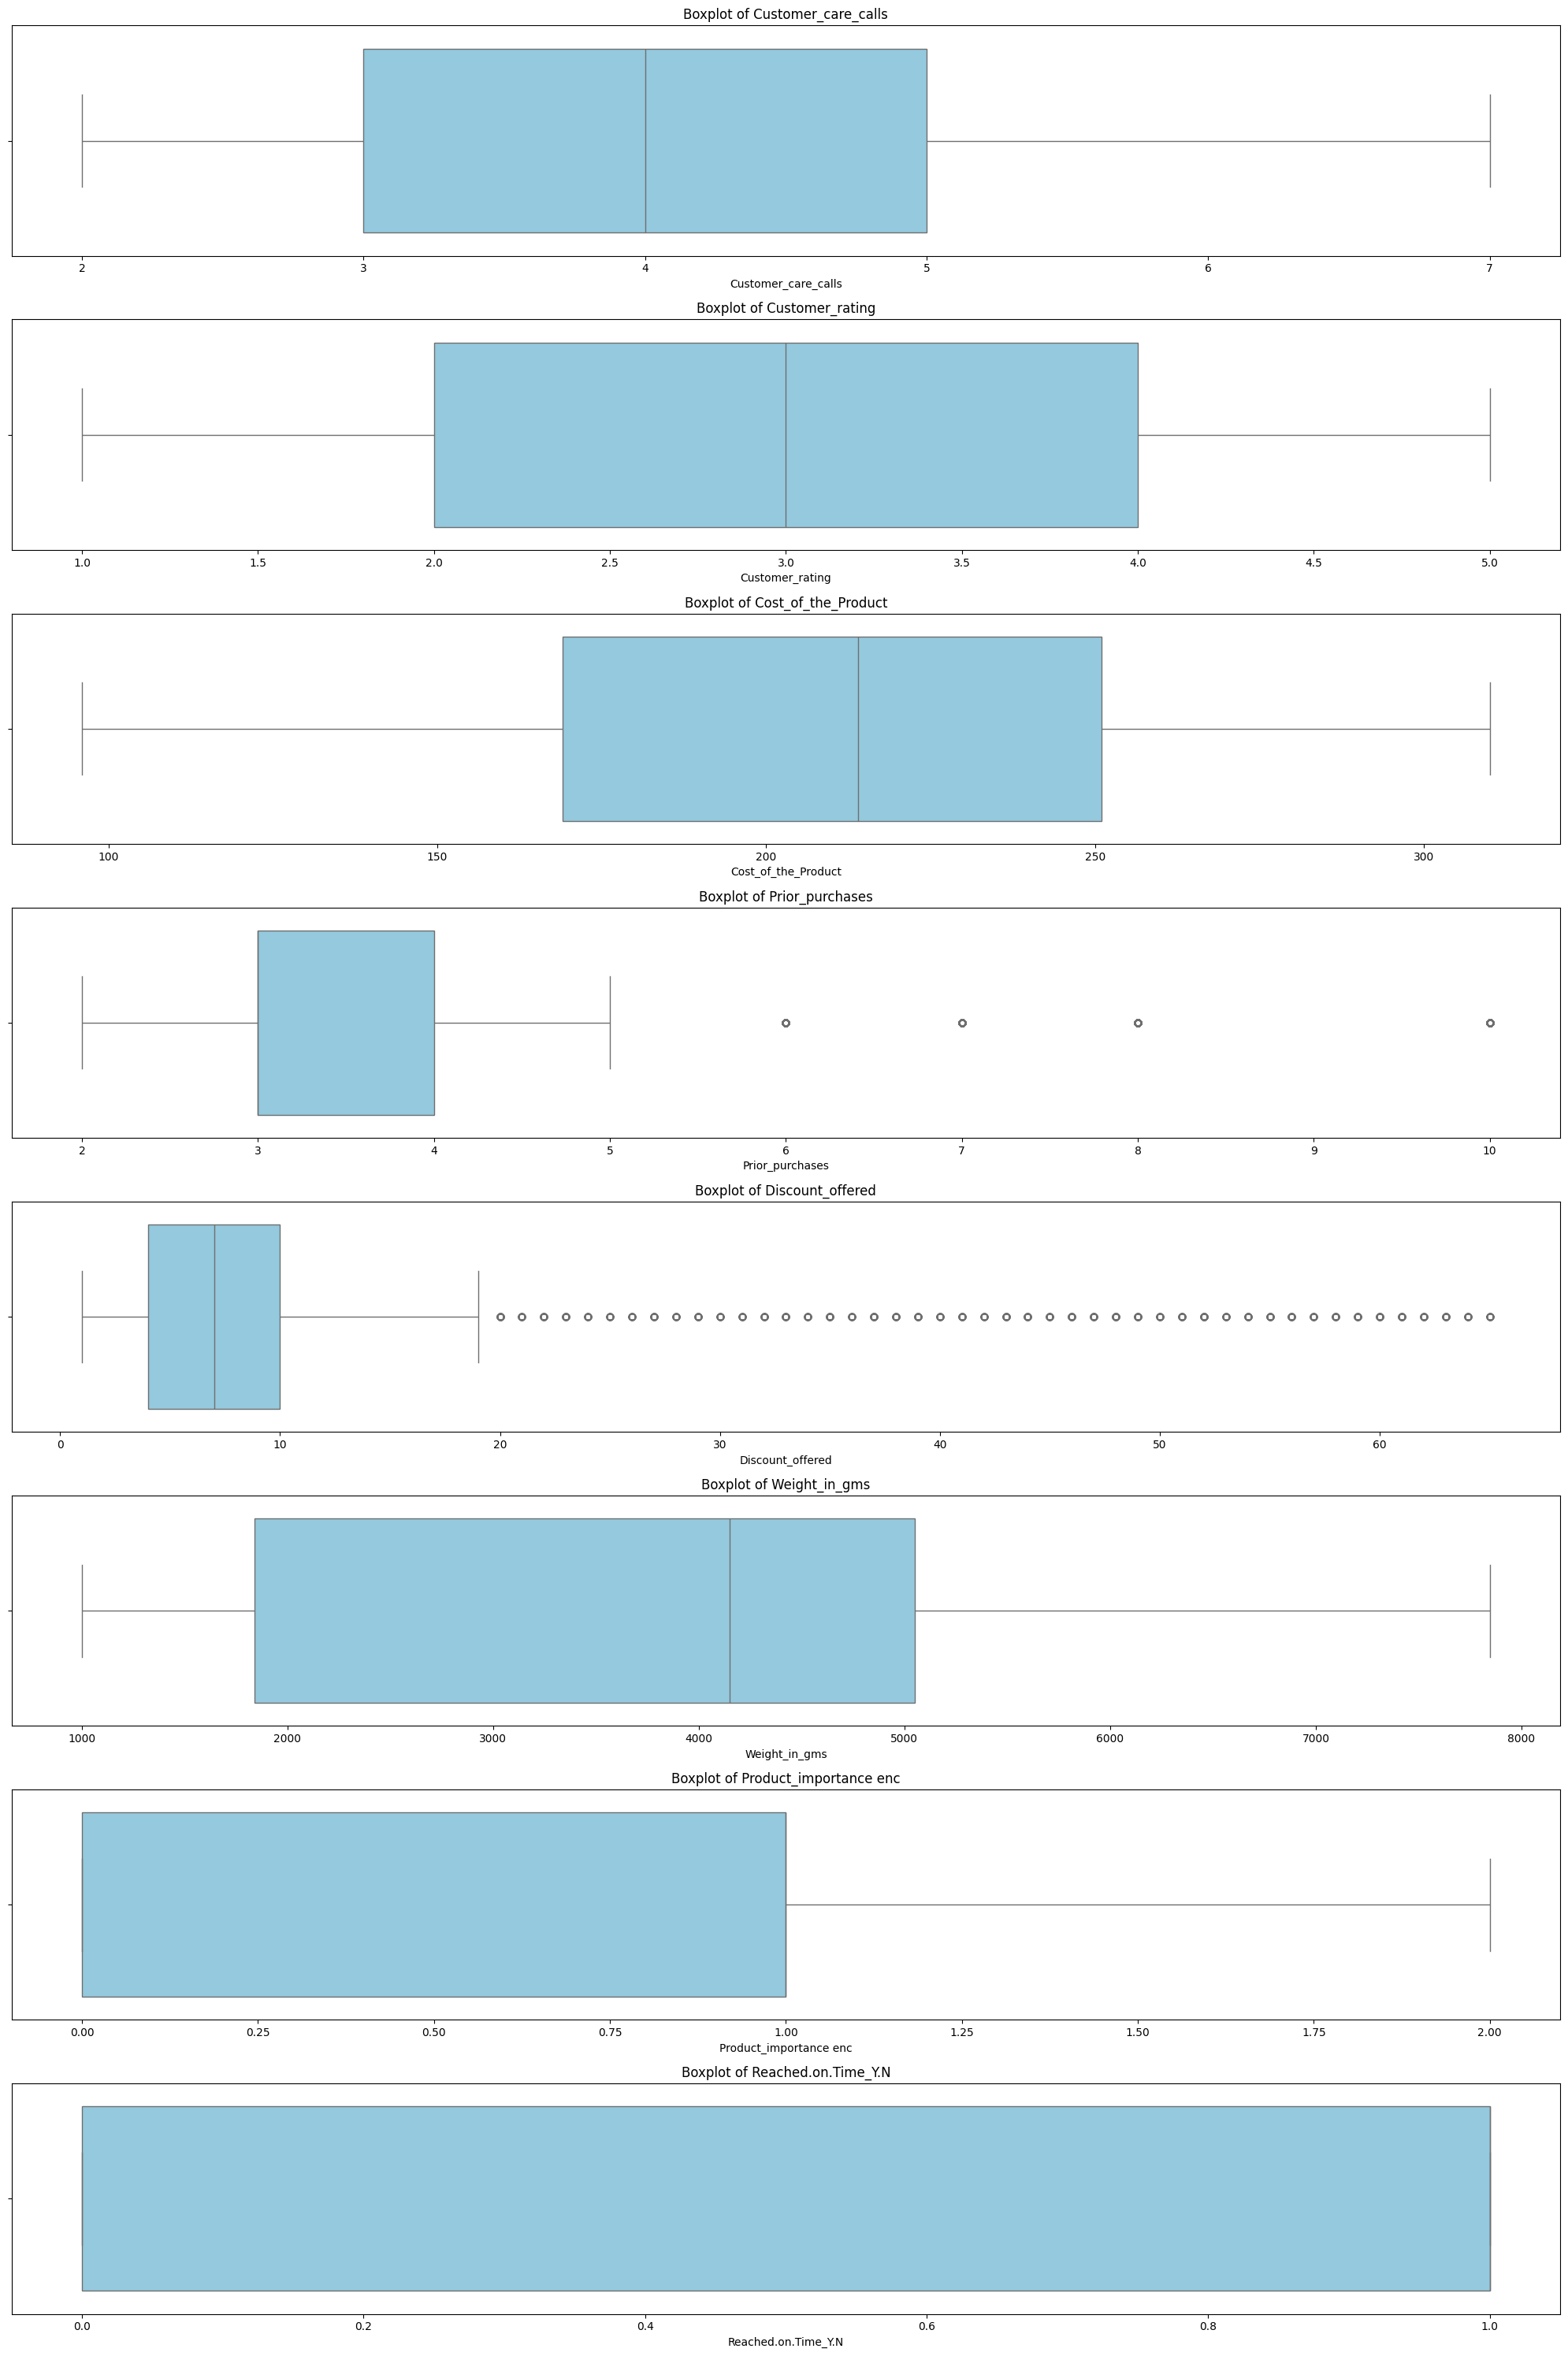

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for boxplot analysis
numeric_cols = dataset.select_dtypes(include=['int64', 'float64']).columns

# Set up the figure
plt.figure(figsize=(20, 30))

# Plot boxplots for each numerical feature including the target variable 'OUTCOME'
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=dataset[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()

In [ ]:
dataset

,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_A,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Flight,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance enc,Gender_F,Gender_M,Reached.on.Time_Y.N
0,4,2,177,3,44,1233,False,False,False,True,False,True,False,False,0,True,False,1
1,4,5,216,2,59,3088,False,False,False,False,True,True,False,False,0,False,True,1
2,2,2,183,4,48,3374,True,False,False,False,False,True,False,False,0,False,True,1
3,3,3,176,4,10,1177,False,True,False,False,False,True,False,False,1,False,True,1
4,2,2,184,3,46,2484,False,False,True,False,False,True,False,False,1,True,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10994,4,1,252,5,1,1538,True,False,False,False,False,False,False,True,1,True,False,1
10995,4,1,232,5,6,1247,False,True,False,False,False,False,False,True,1,True,False,0
10996,5,4,242,5,4,1155,False,False,True,False,False,False,False,True,0,True,False,0
10997,5,2,223,6,2,1210,False,False,False,False,True,False,False,True,1,False,True,0


In [ ]:
numerical_data.nunique()

,0
ID,10999
Customer_care_calls,6
Customer_rating,5
Cost_of_the_Product,215
Prior_purchases,8
Discount_offered,65
Weight_in_gms,4034
Reached.on.Time_Y.N,2


In [ ]:
numerical_data.isnull().sum()

,0
ID,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Discount_offered,0
Weight_in_gms,0
Reached.on.Time_Y.N,0


In [ ]:
# unique values counts
unique_counts=categorical_data.nunique()
print(unique_counts)

Warehouse_block       5
Mode_of_Shipment      3
Product_importance    3
Gender                2
dtype: int64


# **Bar plot on categorical **

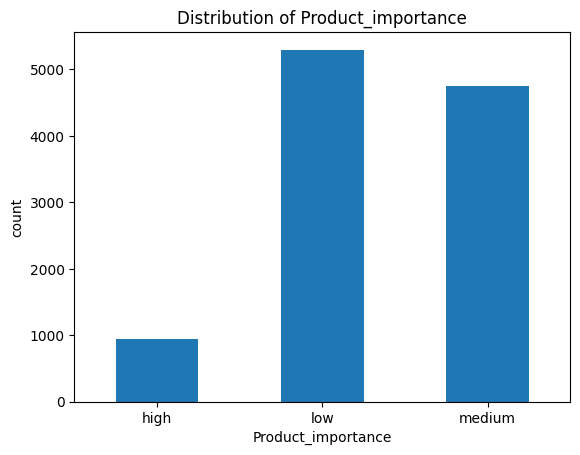

In [ ]:
for col in categorical_features:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    plt.show()

# **Correlation of whole dataset**

In [ ]:
# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()
correlation_matrix


,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
ID,1.000000,0.188998,-0.005722,0.196791,0.145369,-0.598278,0.278312,-0.411822
Customer_care_calls,0.188998,1.000000,0.012209,0.323182,0.180771,-0.130750,-0.276615,-0.067126
Customer_rating,-0.005722,0.012209,1.000000,0.009270,0.013179,-0.003124,-0.001897,0.013119
Cost_of_the_Product,0.196791,0.323182,0.009270,1.000000,0.123676,-0.138312,-0.132604,-0.073587
Prior_purchases,0.145369,0.180771,0.013179,0.123676,1.000000,-0.082769,-0.168213,-0.055515
Discount_offered,-0.598278,-0.130750,-0.003124,-0.138312,-0.082769,1.000000,-0.376067,0.397108
Weight_in_gms,0.278312,-0.276615,-0.001897,-0.132604,-0.168213,-0.376067,1.000000,-0.268793
Reached.on.Time_Y.N,-0.411822,-0.067126,0.013119,-0.073587,-0.055515,0.397108,-0.268793,1.000000


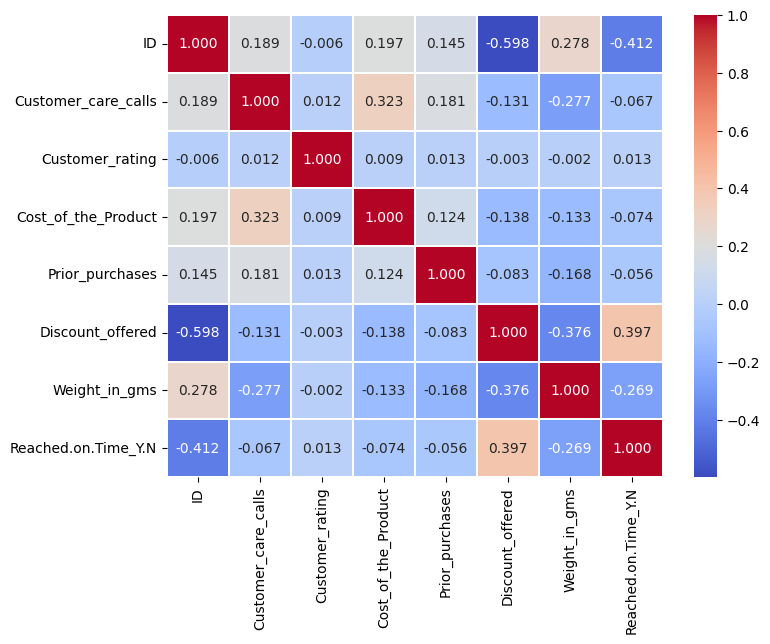

In [ ]:
# Plotting the heatmap for correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.show()

# **Correlation plot between numerical features and target**

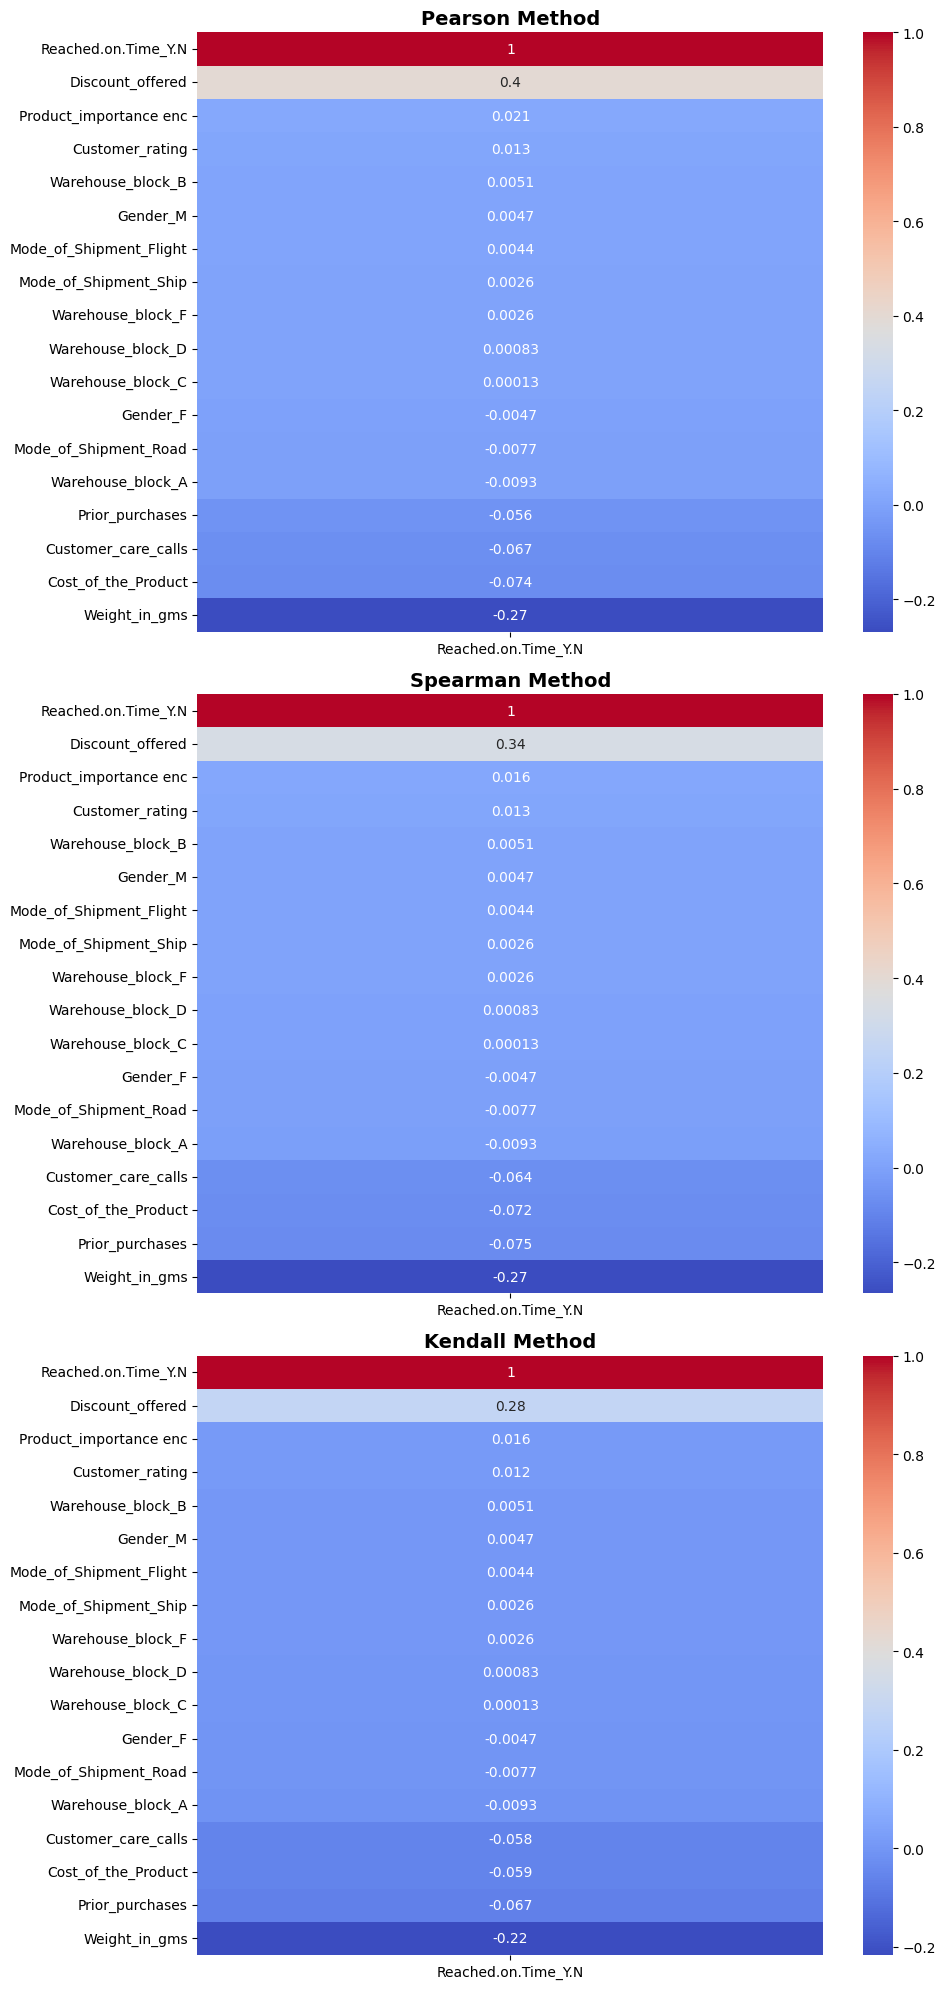

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(3, 1, figsize=(10, 20)) # figsize
## ## Correlation coefficient using different methods
corr1 = dataset.corr('pearson')[['Reached.on.Time_Y.N']].sort_values(by='Reached.on.Time_Y.N', ascending=False)
corr2 = dataset.corr('spearman')[['Reached.on.Time_Y.N']].sort_values(by='Reached.on.Time_Y.N', ascending=False)
corr3 = dataset.corr('kendall')[['Reached.on.Time_Y.N']].sort_values(by='Reached.on.Time_Y.N', ascending=False)

# make the title for each
ax[0].set_title('Pearson Method', fontsize=14, fontweight='bold')
ax[1].set_title('Spearman Method', fontsize=14, fontweight='bold')
ax[2].set_title('Kendall Method', fontsize=14, fontweight='bold')

#Make the Heatmap
sns.heatmap(corr1, ax=ax[0], annot=True, cmap='coolwarm')
sns.heatmap(corr2, ax=ax[1], annot=True, cmap='coolwarm')
sns.heatmap(corr3, ax=ax[2], annot=True, cmap='coolwarm')

plt.tight_layout()
plt.show()

**Density plots of numerical features**

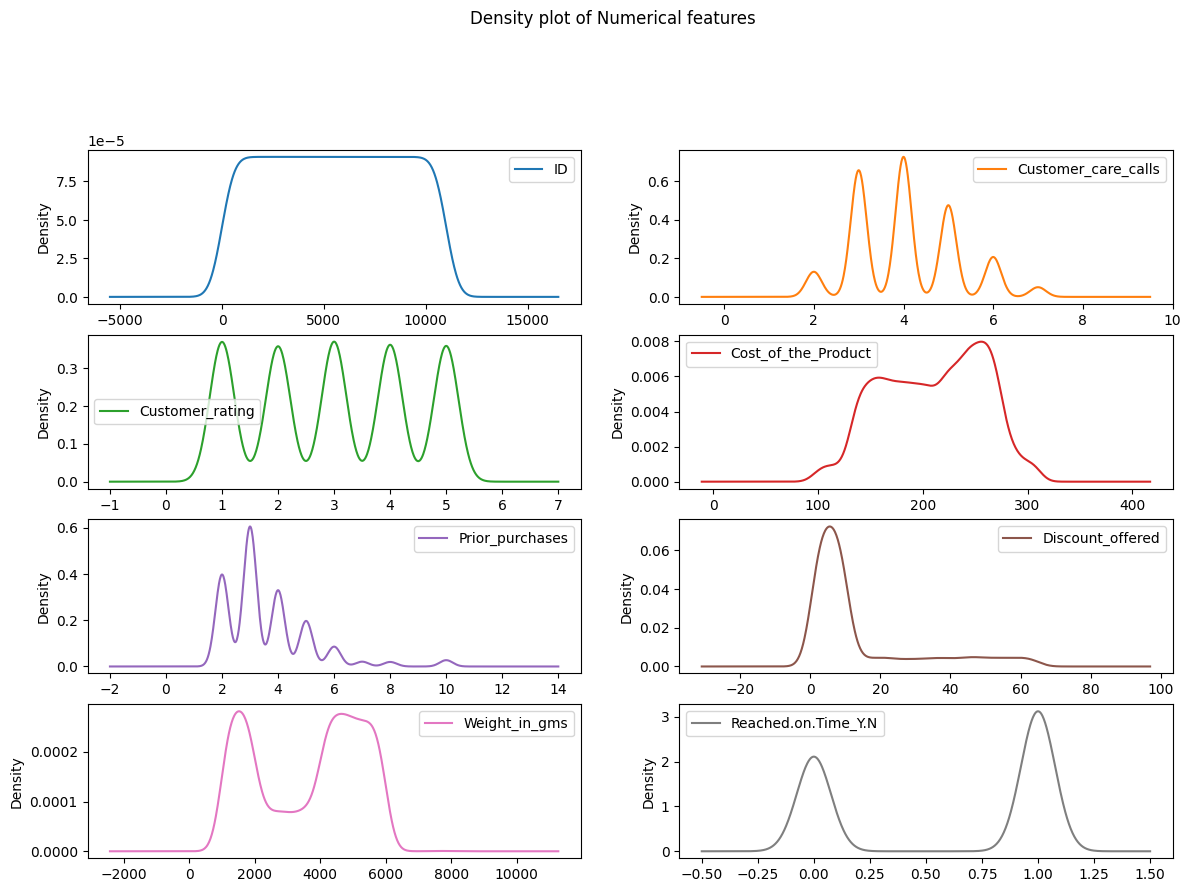

In [ ]:
numerical_data.plot(kind='density',figsize=(14,14),subplots=True,layout=(6,2),title="Density plot of Numerical features",sharex=False)
plt.show()

# **Feature Scaling**

In [ ]:
from sklearn.model_selection import train_test_split

# x er moddhe target baad  e sob input
x = dataset.drop(columns='Reached.on.Time_Y.N')

# y only output column
y = dataset['Reached.on.Time_Y.N']

# data split 80,20
X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=1,
    stratify=dataset['Reached.on.Time_Y.N']
)

print("Training data shape (X_train):", X_train.shape)
print("Testing data shape (X_test):", X_test.shape)

Training data shape (X_train): (8799, 17)
Testing data shape (X_test): (2200, 17)


In [ ]:
from sklearn.preprocessing import MinMaxScaler
minmax_scaler = MinMaxScaler()
minmax_scaler.fit(X_train)

# transform train data
X_train_minmax = minmax_scaler.transform(X_train)

# transform test data
X_test_minmax = minmax_scaler.transform(X_test)

In [ ]:
print("per-feature minimum after scaling:\n {}".format(
    X_train_minmax.min(axis=0)))
print("per-feature maximum after scaling:\n {}".format(
    X_train_minmax.max(axis=0)))

per-feature minimum after scaling:
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
per-feature maximum after scaling:
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### **KNN**

In [ ]:
# preprocessing before scaling
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier()

knn.fit(X_train, y_train)
knn_accuracy_1 = knn.score(X_test, y_test)
print("Test set accuracy without scaling: {:.2f}".format(knn_accuracy_1))

Test set accuracy without scaling: 0.66


In [ ]:
# preprocessing after scaling
knn.fit(X_train_minmax, y_train)
knn_accuracy_2 = knn.score(X_test_minmax, y_test)
# scoring on the scaled test set
print("Test set accuracy after Min-Max Scaling: {:.2f}".format(
    knn_accuracy_2))

Test set accuracy after Min-Max Scaling: 0.62


In [ ]:
accuracy = {}
accuracy['knn'] = max(knn_accuracy_1, knn_accuracy_2)

In [ ]:
accuracy

{'knn': 0.6572727272727272}

## **Logistic regression**

In [ ]:
# logistic regression before scaling
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(max_iter=9000, solver='saga')  # 'saga' also works for large datasets
log_reg.fit(X_train, y_train)

logreg_accuracy_1 = log_reg.score(X_test, y_test)
print("Test set accuracy (Logistic Regression): {:.2f}".format(logreg_accuracy_1))

Test set accuracy (Logistic Regression): 0.62


In [ ]:
# logistic regression after scaling
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(max_iter=9000, solver='saga')
log_reg.fit(X_train_minmax, y_train)

logreg_accuracy_2 =  log_reg.score(X_test_minmax, y_test)
# Scoring on the scaled test set
print("Test set accuracy after Min-Max Scaling (Logistic Regression): {:.2f}".format(
   logreg_accuracy_2))

Test set accuracy after Min-Max Scaling (Logistic Regression): 0.62


In [ ]:
accuracy["logreg"] = max(logreg_accuracy_1, logreg_accuracy_2)

# **Neural network**

In [ ]:
# before scaling feature
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(50, 30),  # 2 hidden layers with 50 and 30 neurons
                    activation='relu',
                    solver='adam',
                    max_iter=9000,
                    random_state=0)

# Train the model
mlp.fit(X_train, y_train)
nn_accuracy_1 = mlp.score(X_test, y_test)
# Evaluate
print("Test set accuracy with Neural Network: {:.2f}".format(nn_accuracy_1))

Test set accuracy with Neural Network: 0.58


In [ ]:
## after scaling feature
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler # cuz it works better for relu
scaler = StandardScaler()
# transform train data
X_train_std = scaler.fit_transform(X_train)

# transform test data
X_test_std = scaler.transform(X_test)

mlp = MLPClassifier(hidden_layer_sizes=(50, 30),  # 2 hidden layers with 50 and 30 neurons
                    activation='relu',
                    solver='adam',
                    max_iter=9000,
                    random_state=0)

# Train the model
mlp.fit(X_train_std, y_train)
nn_accuracy_2 = mlp.score(X_test_std, y_test)
# Evaluate
print("Test set accuracy with Neural Network: {:.2f}".format(nn_accuracy_2))

Test set accuracy with Neural Network: 0.64


In [ ]:
accuracy["nn"] = max(nn_accuracy_1, nn_accuracy_2)

## **Decision Tree**

Training data shape: (8799, 17)
Testing data shape: (2200, 17)


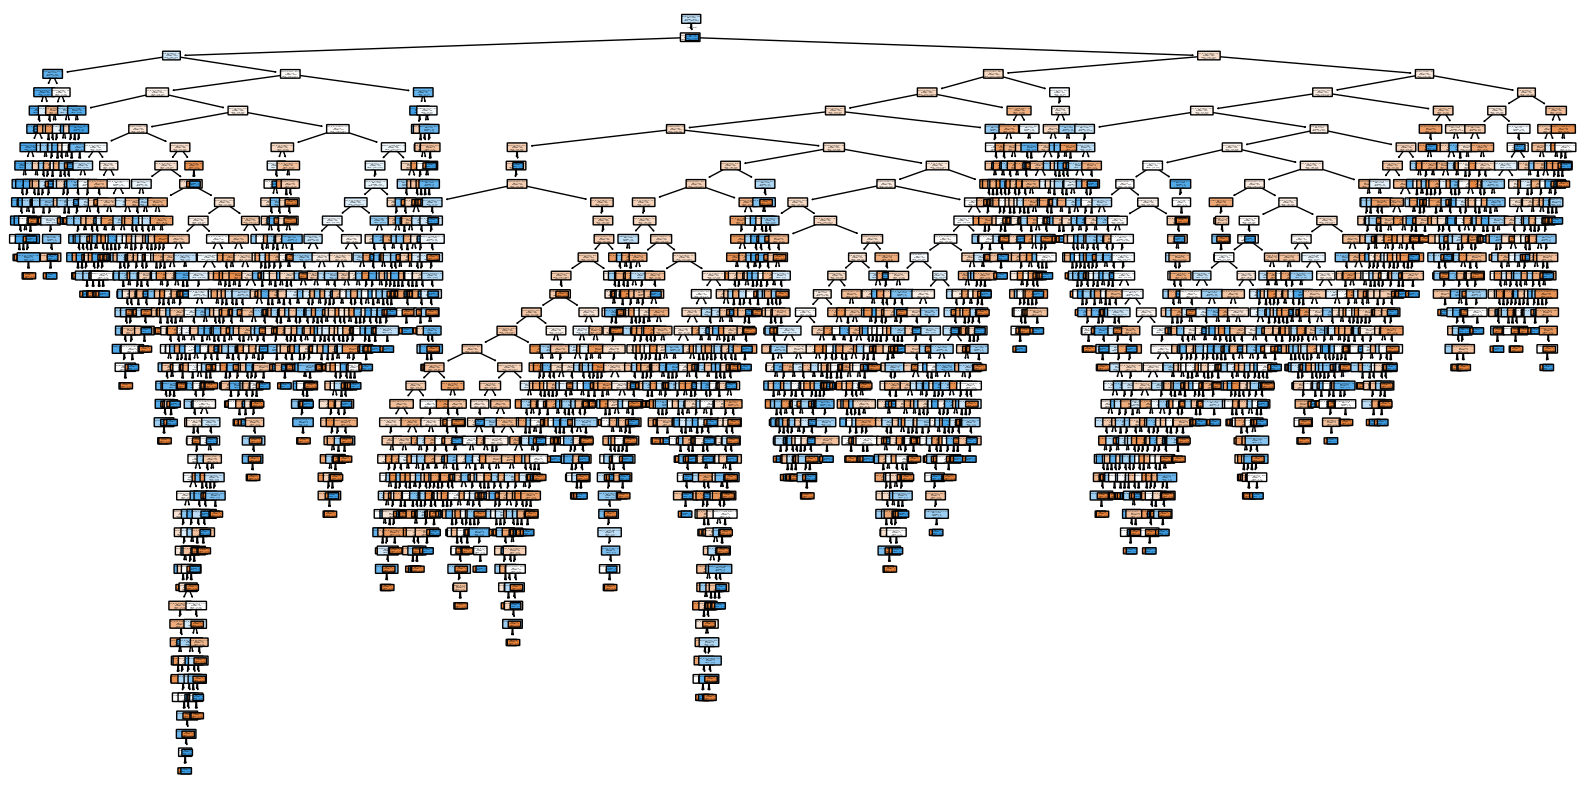

In [ ]:
from sklearn import tree
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# 1. Separate features (x) and the target (y)
x = dataset.drop(columns='Reached.on.Time_Y.N')
y = dataset['Reached.on.Time_Y.N']

# 2. Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=1,
    stratify=dataset['Reached.on.Time_Y.N']
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# 3. Initialize and train (fit) the Decision Tree Classifier
dt = tree.DecisionTreeClassifier()
dt = dt.fit(X_train, y_train)

# 4. Plot the Decision Tree
plt.figure(figsize=(20, 10)) # Makes the plot large enough to read
tree.plot_tree(
    dt,
    filled=True, # Adds colors to the nodes
    feature_names=x.columns, # Shows the actual column names in the boxes
    class_names=['On Time', 'Late'], # Maps 0 and 1 to actual text
    rounded=True
)
plt.show()

In [ ]:
# accuracy calculation
from sklearn.metrics import accuracy_score
y_pred = dt.predict(X_test)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Decision Tree Accuracy:", acc)

Decision Tree Accuracy: 0.6454545454545455


In [ ]:
accuracy["dt"] = acc

In [ ]:
print(accuracy)

{'knn': 0.6572727272727272, 'logreg': 0.6245454545454545, 'nn': 0.6422727272727272, 'dt': 0.6454545454545455}


# **Unsupervised**

In [ ]:
# K_Means_cluster
from sklearn.cluster import KMeans

def implement_KMC(df_temp,cluster_num):
  km = KMeans(n_clusters=cluster_num)  #defining the cluster number
  y_predicted = km.fit_predict(df_temp[df_temp.columns])
  return km,y_predicted #returns the model and the predicted assigned cluster to each entry

cluster = 2
dataset_kmeans = x
km,y_predicted = implement_KMC(dataset_kmeans,cluster)  ##stores the model and the predicted values
dataset_kmeans["kmeans_cluster"]=y_predicted
dataset_kmeans.head(10)

,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_A,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Flight,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance enc,Gender_F,Gender_M,kmeans_cluster
0,4,2,177,3,44,1233,False,False,False,True,False,True,False,False,0,True,False,1
1,4,5,216,2,59,3088,False,False,False,False,True,True,False,False,0,False,True,1
2,2,2,183,4,48,3374,True,False,False,False,False,True,False,False,0,False,True,0
3,3,3,176,4,10,1177,False,True,False,False,False,True,False,False,1,False,True,1
4,2,2,184,3,46,2484,False,False,True,False,False,True,False,False,1,True,False,1
5,3,1,162,3,12,1417,False,False,False,False,True,True,False,False,1,True,False,1
6,3,4,250,3,3,2371,False,False,False,True,False,True,False,False,0,True,False,1
7,4,1,233,2,48,2804,False,False,False,False,True,True,False,False,0,True,False,1
8,3,4,150,3,11,1861,True,False,False,False,False,True,False,False,0,True,False,1
9,3,2,164,3,29,1187,False,True,False,False,False,True,False,False,1,True,False,1


# **plotting the clusters by DIMENSIONALITY REDUCTION (PCA) **bold text**

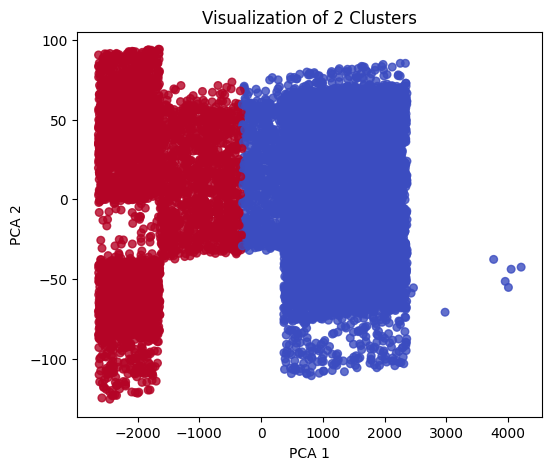

In [ ]:
## before scaling

#Plot the 2 clusters with different color from the prediciton value
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Run KMeans with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=1, n_init=10)
cluster_label = kmeans.fit_predict(x)   # <-- this creates the 'labels' array

# 3. Reduce to 2D for visualization
pca = PCA(n_components=2)
X_2d = pca.fit_transform(x)

# 4. Plot clusters
plt.figure(figsize=(6,5))
plt.scatter(X_2d[:,0], X_2d[:,1], c=cluster_label, cmap='coolwarm', s=30, alpha=0.8)
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Visualization of 2 Clusters")
plt.show()

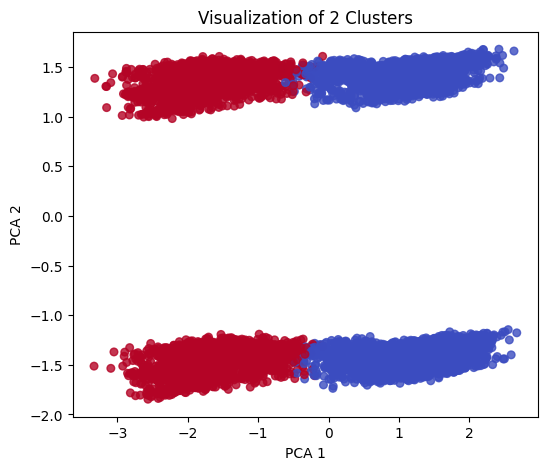

In [ ]:
# after scaling
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(x)

# 2. Run KMeans with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=1, n_init=10)
cluster_label = kmeans.fit_predict(X_scaled)   # <-- this creates the 'labels' array

# 3. Reduce to 2D for visualization
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

# 4. Plot clusters
plt.figure(figsize=(6,5))
plt.scatter(X_2d[:,0], X_2d[:,1], c=cluster_label, cmap='coolwarm', s=30, alpha=0.8)
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Visualization of 2 Clusters")
plt.show()

In [ ]:
#mapping their behavior pattern to give them a categorization and adding it into the dataframe

label_map = {0: 'cluster_1', 1: 'cluster_2'}
dataset_kmeans['kmeans_cluster'] = dataset_kmeans['kmeans_cluster'].map(label_map)
display(dataset_kmeans.head(10))

,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_A,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Flight,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance enc,Gender_F,Gender_M,kmeans_cluster
0,4,2,177,3,44,1233,False,False,False,True,False,True,False,False,0,True,False,cluster_2
1,4,5,216,2,59,3088,False,False,False,False,True,True,False,False,0,False,True,cluster_2
2,2,2,183,4,48,3374,True,False,False,False,False,True,False,False,0,False,True,cluster_1
3,3,3,176,4,10,1177,False,True,False,False,False,True,False,False,1,False,True,cluster_2
4,2,2,184,3,46,2484,False,False,True,False,False,True,False,False,1,True,False,cluster_2
5,3,1,162,3,12,1417,False,False,False,False,True,True,False,False,1,True,False,cluster_2
6,3,4,250,3,3,2371,False,False,False,True,False,True,False,False,0,True,False,cluster_2
7,4,1,233,2,48,2804,False,False,False,False,True,True,False,False,0,True,False,cluster_2
8,3,4,150,3,11,1861,True,False,False,False,False,True,False,False,0,True,False,cluster_2
9,3,2,164,3,29,1187,False,True,False,False,False,True,False,False,1,True,False,cluster_2


In [ ]:
dataset_kmeans['kmeans_cluster'].value_counts()

,count
kmeans_cluster,
cluster_1,6597
cluster_2,4402


# **Compare the model**

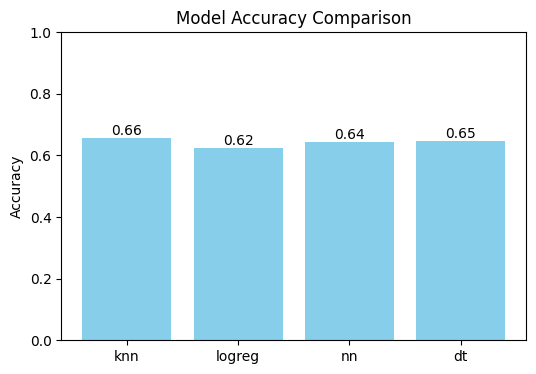

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.bar(accuracy.keys(), accuracy.values(), color="skyblue")

plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 1)  # since accuracy is between 0 and 1

# add text labels on bars
for i, (model, acc) in enumerate(accuracy.items()):
    plt.text(i, acc + 0.01, f"{acc:.2f}", ha="center")

plt.show()

# **Precision and Recall compare**

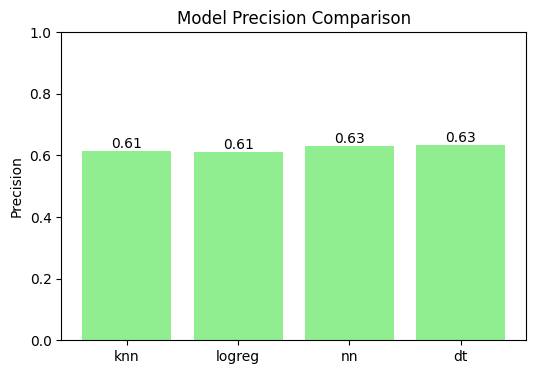

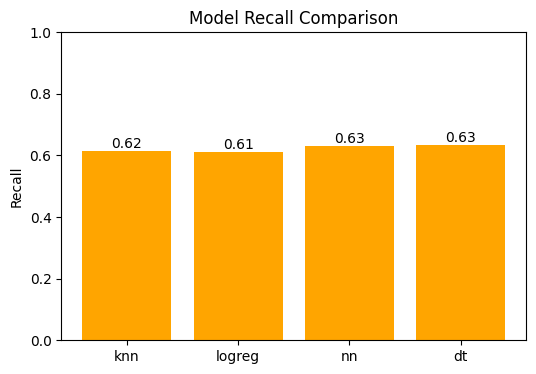

In [ ]:
from sklearn.metrics import precision_score, recall_score
y_true = y_test

precisions = {}
recalls = {}

#knn
y_pred_knn = knn.predict(X_test_minmax)
precisions["knn"] = precision_score(y_true, y_pred_knn, average="macro")
recalls["knn"]    = recall_score(y_true, y_pred_knn, average="macro")

#logreg
y_pred_log = log_reg.predict(X_test_minmax)
precisions["logreg"] = precision_score(y_true, y_pred_log, average="macro")
recalls["logreg"]    = recall_score(y_true, y_pred_log, average="macro")

# mlp (nn)
y_pred_nn = mlp.predict(X_test_std)
precisions["nn"] = precision_score(y_true, y_pred_nn, average="macro")
recalls["nn"]    = recall_score(y_true, y_pred_nn, average="macro")

# dt
y_pred_dt = dt.predict(X_test)
precisions["dt"] = precision_score(y_true, y_pred_dt, average="macro")
recalls["dt"]    = recall_score(y_true, y_pred_dt, average="macro")

#Plot Precision
plt.figure(figsize=(6,4))
plt.bar(precisions.keys(), precisions.values(), color="lightgreen")
plt.ylabel("Precision")
plt.title("Model Precision Comparison")
plt.ylim(0,1)
for i, (model, prec) in enumerate(precisions.items()):
    plt.text(i, prec + 0.01, f"{prec:.2f}", ha="center")
plt.show()

#Plot Recall
plt.figure(figsize=(6,4))
plt.bar(recalls.keys(), recalls.values(), color="orange")
plt.ylabel("Recall")
plt.title("Model Recall Comparison")
plt.ylim(0,1)
for i, (model, rec) in enumerate(recalls.items()):
    plt.text(i, rec + 0.01, f"{rec:.2f}", ha="center")
plt.show()


# **Confusion Matrix**

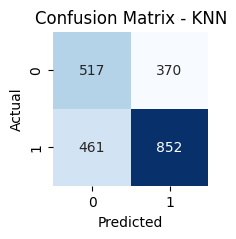

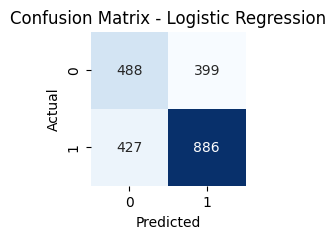

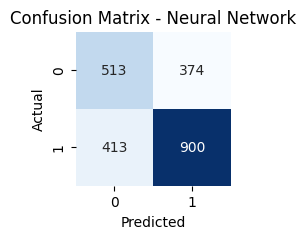

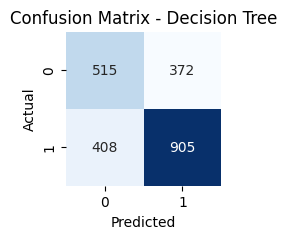

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

models = {
    "KNN": knn,
    "Logistic Regression": log_reg,
    "Neural Network": mlp,
    "Decision Tree": dt
}

for name, model in models.items():
    if name in ["KNN", "Logistic Regression"]:
        X_eval = X_test_minmax
    elif name == "Neural Network":
        X_eval = X_test_std
    else:
        X_eval = X_test
    y_pred = model.predict(X_eval)
    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot
    plt.figure(figsize=(2,2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# **AUC and ROC**

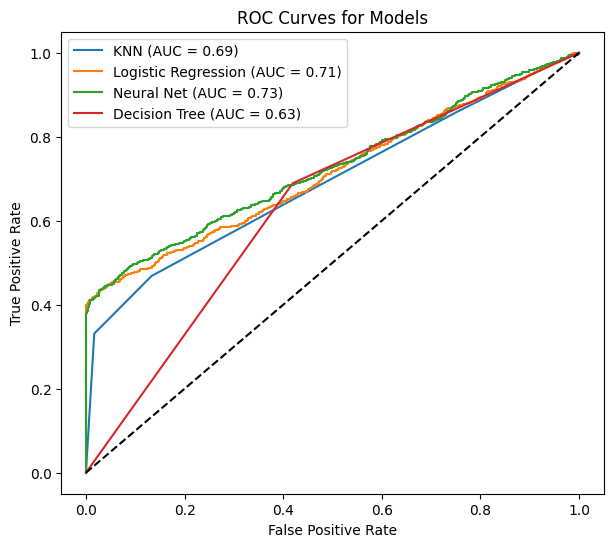

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

models = {
    "KNN": knn,
    "Logistic Regression": log_reg,
    "Neural Net": mlp,
    "Decision Tree": dt
}

plt.figure(figsize=(7,6))

for name, model in models.items():
    if name in ["KNN", "Logistic Regression"]:
        X_eval = X_test_minmax
    elif name == "Neural Net":
        X_eval = X_test_std
    else:
        X_eval = X_test

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_eval)[:,1]   # prob for cls1
    else:
        y_score = model.decision_function(X_eval)    # fallback

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc_score = roc_auc_score(y_test, y_score)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.2f})")

# reference line (random guess)
plt.plot([0,1], [0,1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Models")
plt.legend()
plt.show()

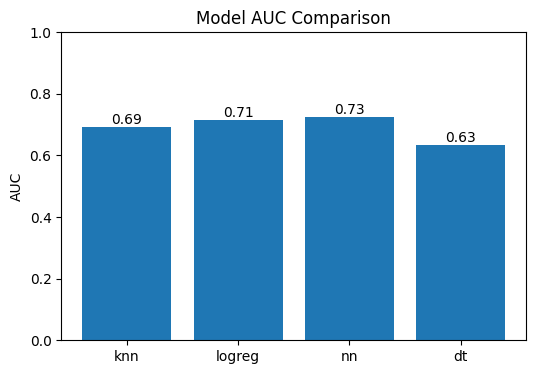

In [ ]:
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

models = {
    "knn": knn,
    "logreg": log_reg,
    "nn": mlp,
    "dt": dt,
}

# compute AUCs (binary: uses class-1 scores)
aucs = {}
for name, model in models.items():
    if name in ["knn", "logreg"]:
        X_eval = X_test_minmax
    elif name == "nn":
        X_eval = X_test_std
    else:
        X_eval = X_test

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_eval)[:, 1]
    else:
        y_score = model.decision_function(X_eval)
    aucs[name] = roc_auc_score(y_test, y_score)

# bar chart
plt.figure(figsize=(6,4))
plt.bar(aucs.keys(), aucs.values())
plt.ylabel("AUC")
plt.title("Model AUC Comparison")
plt.ylim(0, 1)
for i, (model, aucv) in enumerate(aucs.items()):
    plt.text(i, aucv + 0.01, f"{aucv:.2f}", ha="center")
plt.show()
